# Is this logical gate transversal?

> **In short.**
> * **The setting.** A *code block* is a group of physical qubits that together hold protected (logical) qubits. A gate on a code block is safe against a single fault when no gate joins two qubits of the same block: then one fault can damage at most one qubit per block, and the code repairs it. Such a gate is called **transversal**.
> * **The question.** Given a block of gates, does it do the intended logical operation, and is it transversal?
> * **The answer, on four examples.** The textbook CNOT between two Steane blocks is both. The same CNOT with four extra gates that cancel is still the right operation, but not transversal: the extra gates link two qubits of one block. A SWAP inside the [[4,2,2]] code is a logical CNOT but not transversal. H on every qubit of the [[4,2,2]] code is transversal, but its operation is not on the tool's list of named gates.
> * **How to read the pictures.** Each program is drawn with one horizontal line per qubit and time running left to right; each block has its own shade. A CNOT is a green dot joined to a red dot. The small diagrams are what the tool reduces a block to: one line per *logical* qubit.
> * New to codes and ZX-diagrams? Start with [TInjectionWalkthrough.ipynb](TInjectionWalkthrough.ipynb), Part A.

A logical gate is **transversal** when a single fault cannot spread to two qubits of the same code block. Transversal gates are the simplest fault-tolerant gates: a fault they cause stays a single-qubit error in each block, which the code can correct.

The role **`transversal gate`** adds this check to those of `logical gate` (one logical operation, in every run). The check looks at the block's multi-qubit gates and groups the qubits they **connect, directly or through a chain of gates**. The block is transversal when every group holds at most one qubit of each code block (the code before the block). The chain matters: `CNOT(0 -> 7)` followed by `CNOT(7 -> 1)` uses a different block in each gate, but a fault on qubit 0 can reach qubit 1.

The role `logical gate` does not ask for this: a logical gate need not be transversal (lattice surgery, for example), and is not wrong for that.

In [1]:
%matplotlib inline
import sys
sys.path.insert(0, '..')                      # for the test suite's Steane encoder
import itertools
import numpy as np
from pyzx.circuit import Circuit
from pyzx.circuit.gates import CNOT, HAD, SWAP
import pyzx as zx
from zxqec.qprogram import QProgram
from zxqec.spacetime import Topology, draw_program, draw_program_slices
from tests.programs import steane_encoder

def two_steane_blocks(gates, name):
    """Two Steane blocks (qubits 0-6 and 7-13, inputs on qubits 3 and 10), then ``gates``.

    The qubits are laid out on a 2 x 7 grid: the first block is one row, the second the other."""
    p = QProgram(14, initial_states={q: '0' for q in range(14) if q not in (3, 10)},
                 topology=Topology.grid(2, 7))
    c = Circuit(14)
    for g in steane_encoder(list(range(7))) + steane_encoder(list(range(7, 14))):
        c.add_gate(g)
    p.add_circuit(c, name='encode both')
    c = Circuit(14)
    for g in gates:
        c.add_gate(g)
    p.add_circuit(c, name=name)
    level = p.group_stages([(0, 0, 'encode both', 'encoder'), (1, 1, name, 'transversal gate')])
    return p, level, p.summary(level)

## 1. The transversal CNOT between two Steane blocks

`CNOT(q -> 7 + q)` for every `q`: each gate joins qubit `q` of the first block to qubit `q` of the second, and nothing else.

In [2]:
p, level, s = two_steane_blocks([CNOT(q, 7 + q) for q in range(7)], 'transversal CNOT')
print(s.table())
print()
print(s.blocks[1].describe())

block               role              code before            code after             logical action  every run?  checks
0 encode both       encoder           [[1,1,1]] + [[1,1,1]]  [[7,1,3]] + [[7,1,3]]  I               yes         ok
1 transversal CNOT  transversal gate  [[7,1,3]] + [[7,1,3]]  [[7,1,3]] + [[7,1,3]]  CNOT(0->1)      yes         ok

Block 1 'transversal CNOT' (transversal gate) -- stages 1
  code before: [[7,1,3]] on qubits 0,1,2,3,4,5,6; [[7,1,3]] on qubits 7,8,9,10,11,12,13
  code after:  [[7,1,3]] on qubits 0,1,2,3,4,5,6; [[7,1,3]] on qubits 7,8,9,10,11,12,13
  logical action: deterministic: every run implements CNOT(0->1)
  ok      implements CNOT(0->1) in every run
  ok      transversal: no two qubits of one code block are connected by its gates


The program: qubits 0-6 are the first block and 7-13 the second, each encoded by its own circuit (first shade), then the seven CNOTs (second shade). The seven CNOTs act at the same time step, so here they are drawn on top of each other, as the bundle of arcs at the right edge.

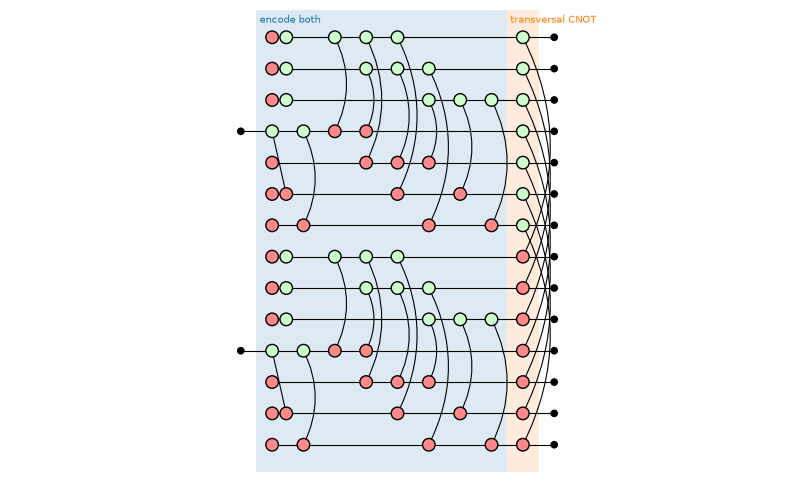

In [3]:
draw_program(p, level=level, show_time=False, figsize=(10, 6))

The same step seen from above the chip. The program's qubits are laid out on a 2 x 7 grid, the first block (qubits 0-6) as the bottom row and the second (7-13) as the top row (the faint lines), and the slice at the time step of the CNOTs shows its gates (`draw_program_slices`). Every CNOT joins a qubit of the bottom row (green, the control) to the qubit right above it (red, the target), never two qubits of the same row: that is what *transversal* means.

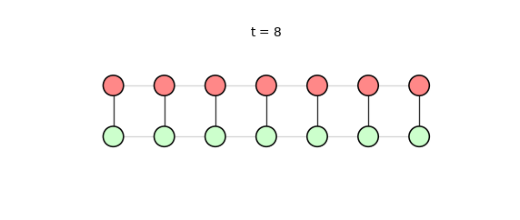

In [4]:
draw_program_slices(p, stage=1, cols=1, panel=(5, 2))

And what the tool reduces the CNOT block to, between the ideal encoders before it and the ideal decoders after it: one line per logical qubit, a green dot on the first joined to a red dot on the second. That is the ZX-diagram of a CNOT from the first logical qubit to the second.

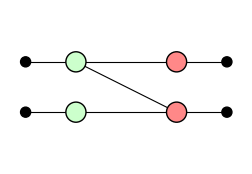

In [5]:
zx.draw_matplotlib(s.blocks[1].action.graph, figsize=(3, 2))

A logical `CNOT` from the first block to the second, in every run, and transversal.

## 2. The same logical CNOT, with a chain that undoes itself

Now the same seven `CNOT`s, followed by `CNOT(0 -> 7)`, `CNOT(7 -> 1)`, `CNOT(7 -> 1)`, `CNOT(0 -> 7)`. The four extra gates cancel, so the logical operation is unchanged. But each of them joins the two blocks, and together they connect qubits 0 and 1 of the first block through qubit 7: a fault between them could reach both.

In [6]:
extra = [CNOT(0, 7), CNOT(7, 1), CNOT(7, 1), CNOT(0, 7)]
p, level, s = two_steane_blocks([CNOT(q, 7 + q) for q in range(7)] + extra, 'CNOT, and a chain')
print(s.table())
print()
print(s.blocks[1].describe())

block                role              code before            code after             logical action  every run?  checks
0 encode both        encoder           [[1,1,1]] + [[1,1,1]]  [[7,1,3]] + [[7,1,3]]  I               yes         ok
1 CNOT, and a chain  transversal gate  [[7,1,3]] + [[7,1,3]]  [[7,1,3]] + [[7,1,3]]  CNOT(0->1)      yes         1 problem(s)

Block 1 'CNOT, and a chain' (transversal gate) -- stages 1
  code before: [[7,1,3]] on qubits 0,1,2,3,4,5,6; [[7,1,3]] on qubits 7,8,9,10,11,12,13
  code after:  [[7,1,3]] on qubits 0,1,2,3,4,5,6; [[7,1,3]] on qubits 7,8,9,10,11,12,13
  logical action: deterministic: every run implements CNOT(0->1)
  ok      implements CNOT(0->1) in every run
  PROBLEM not transversal: its gates connect qubits 0, 1 of the code block on qubits 0,1,2,3,4,5,6


The block, one time step at a time on the grid (bottom row: qubits 0-6, top row: 7-13): the seven CNOTs across, then the chain of four. At t = 9 qubit 0 is joined to qubit 7 above it, and at t = 10 qubit 7 to qubit 1, back in the bottom row: one path of gates links two qubits of the first block.

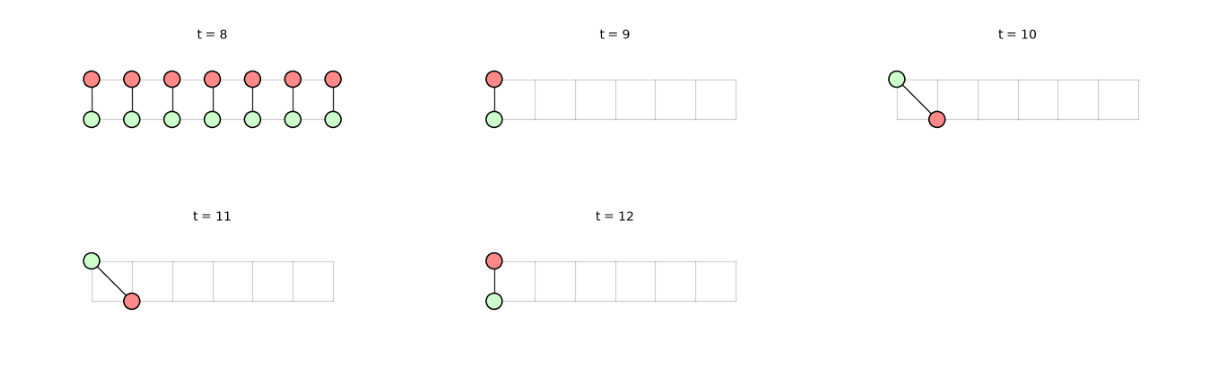

In [7]:
draw_program_slices(p, stage=1, cols=3, panel=(4, 1.8))

Still a logical `CNOT` in every run, so it passes as a `logical gate`; as a `transversal gate` it does not, and the report names the two qubits and their block.

## 3. A logical gate by a SWAP inside the block: the [[4,2,2]] code

The [[4,2,2]] code holds two logical qubits in four physical ones, with stabilizers `XXXX` and `ZZZZ`. Swapping two of its physical qubits maps the code to itself and acts on the logical qubits, so it is a logical gate. It is not transversal: the `SWAP` joins two qubits of the one block.

In [8]:
def four_two_two(gates, name):
    """The [[4,2,2]] code, inputs on qubits 0 and 1, then ``gates``."""
    p = QProgram(4, initial_states={2: '0', 3: '+'})
    c = Circuit(4)
    for g in (CNOT(1, 0), CNOT(0, 2), CNOT(1, 2), CNOT(3, 0), CNOT(3, 1), CNOT(3, 2)):
        c.add_gate(g)
    p.add_circuit(c, name='encode')
    c = Circuit(4)
    for g in gates:
        c.add_gate(g)
    p.add_circuit(c, name=name)
    level = p.group_stages([(0, 0, 'encode', 'encoder'), (1, 1, name, 'transversal gate')])
    return p, level, p.summary(level)

p, level, s = four_two_two([SWAP(0, 1)], 'SWAP qubits 0 and 1')
print(p.code_at(0))
print()
print(s.table())
print()
print(s.blocks[1].describe())

[[4, 2, 2]] CSS code on qubits 0, 1, 2, 3
    stabilizer +XXXX
    stabilizer +ZZZZ
    logical X XIXI   logical Z ZZII
    logical X XXII   logical Z ZIZI

block                  role              code before            code after  logical action  every run?  checks
0 encode               encoder           [[1,1,1]] + [[1,1,1]]  [[4,2,2]]   I               yes         ok
1 SWAP qubits 0 and 1  transversal gate  [[4,2,2]]              [[4,2,2]]   CNOT(0->1)      yes         1 problem(s)

Block 1 'SWAP qubits 0 and 1' (transversal gate) -- stages 1
  code before: [[4,2,2]] on qubits 0,1,2,3
  code after:  [[4,2,2]] on qubits 0,1,2,3
  logical action: deterministic: every run implements CNOT(0->1)
  ok      implements CNOT(0->1) in every run
  PROBLEM not transversal: its gates connect qubits 0, 1 of the code block on qubits 0,1,2,3


The program: the encoder of the [[4,2,2]] code (first shade), then the SWAP (second shade), drawn as three CNOTs, which is how PyZX writes a SWAP. All four qubits are one code block, so the SWAP joins two qubits of the same block.

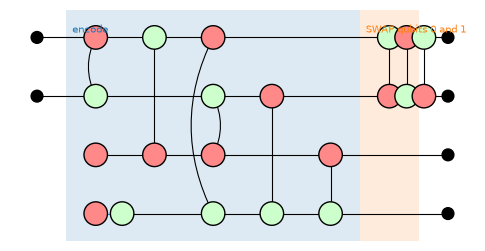

In [9]:
draw_program(p, level=level, show_time=False, figsize=(6, 3))

The reduced block is the picture of section 1: a green dot on the first logical qubit joined to a red dot on the second, a logical `CNOT(0 -> 1)`.

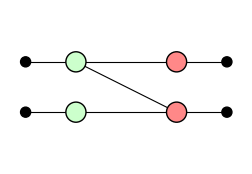

In [10]:
zx.draw_matplotlib(s.blocks[1].action.graph, figsize=(3, 2))

In the code's logical operators (`XIXI`, `ZZII` for the first logical qubit, `XXII`, `ZIZI` for the second), swapping qubits 0 and 1 turns `XIXI` into `IXXI`, which is the product of the two logical `X`s, and `ZIZI` into `IZZI`, the product of the two logical `Z`s: that is a logical `CNOT(0 -> 1)`, as the tool says. A logical gate, but not a transversal one.

## 4. H on every qubit of the [[4,2,2]] code: transversal, but not one of the named gates

`H` on every qubit keeps the [[4,2,2]] code (it exchanges `XXXX` and `ZZZZ`) and is transversal. Its logical action is `H` on both logical qubits and a swap of the two. The tool computes that action exactly, but names only single gates from a short list (single-qubit Cliffords, `T`, `T^dag`, `CNOT`, `CZ`, `SWAP`, and some states and measurements), so it reports the operation as *not recognised*, and the role check counts that as a problem:

In [11]:
p, level, s = four_two_two([HAD(q) for q in range(4)], 'H on every qubit')
print(s.table())
print()
print(s.blocks[1].describe())

block               role              code before            code after  logical action  every run?  checks
0 encode            encoder           [[1,1,1]] + [[1,1,1]]  [[4,2,2]]   I               yes         ok
1 H on every qubit  transversal gate  [[4,2,2]]              [[4,2,2]]   not recognised  yes         1 problem(s)

Block 1 'H on every qubit' (transversal gate) -- stages 1
  code before: [[4,2,2]] on qubits 0,1,2,3
  code after:  [[4,2,2]] on qubits 0,1,2,3
  logical action: deterministic: every run implements a map outside the list of named operations
  PROBLEM in some run the block does something that is not a recognised logical operation (for example it leaves the code)
  ok      implements an operation outside the named list in every run
  ok      transversal: no two qubits of one code block are connected by its gates


What the tool reduces the block to: the two input wires are Hadamard edges (the thin blue lines), that is an H on each logical qubit, and the two wires then cross, a swap.

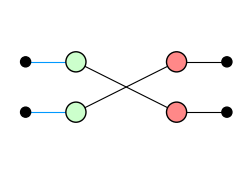

In [12]:
zx.draw_matplotlib(s.blocks[1].action.graph, figsize=(3, 2))

The action itself is right. Its matrix equals `SWAP (H x H)` exactly (up to a scalar):

In [13]:
act = s.blocks[1].action
m = act.matrix(act.branches()[0].outcomes)
H = np.array([[1, 1], [1, -1]]) / np.sqrt(2)
SWAP_M = np.eye(4)[[0, 2, 1, 3]]
target = SWAP_M @ np.kron(H, H)
i = np.unravel_index(np.argmax(np.abs(target)), target.shape)
print("equal to SWAP (H x H) up to a scalar:", np.allclose(m * (target[i] / m[i]), target))

equal to SWAP (H x H) up to a scalar: True


## Summary

| block | logical action | transversal? |
|---|---|---|
| `CNOT(q -> 7+q)` on two Steane blocks | `CNOT` | yes |
| the same, with a chain that undoes itself | `CNOT` | no: qubits 0 and 1 of the first block are connected |
| `SWAP` inside the [[4,2,2]] code | `CNOT(0 -> 1)` | no: the `SWAP` joins two qubits of the block |
| `H` on every qubit of the [[4,2,2]] code | `SWAP (H x H)`, not a named gate | yes |

What the check does **not** do:

* it looks at the gates of the block, as written; a *permutation* stage, which relabels qubits without gates, has nothing to check;
* it says whether a single fault can spread inside a block through the gates; it is not a full fault-tolerance analysis (measurements, classical control and noise are not considered).

The same cases are in the test suite (`tests/test_codes.py`).